# Exploratory Data Analysis: Deteksi Sarkasme pada Dataset SARC

Notebook ini mengenali dataset SARC (Self-Annotated Reddit Corpus) versi balanced sebelum model RoBERTa dan DistilBERT dilatih. Dataset berisi pasangan parent comment dan comment dari Reddit, dengan label 1 untuk comment sarkas.

Cleaning di notebook ini sama persis dengan `02_preprocessing`, yaitu cleaning ringan: hanya HTML entity, link markdown, URL, tag HTML, dan spasi yang dirapikan. Huruf kapital, tanda baca, dan mention dibiarkan karena bisa menjadi petunjuk sarkasme. Jadi data yang dianalisis di sini sama dengan data yang dipakai untuk training.

Tujuan EDA:
1. Mengecek kualitas data mentah (data kosong, duplikat, label bertentangan, HTML, URL).
2. Melihat hasil cleaning ringan.
3. Melihat distribusi label, panjang teks, subreddit, skor, dan waktu.
4. Melihat pola kata pada comment sarkas dan bukan sarkas.
5. Melihat hubungan antara comment dan parent comment.
6. Mengecek panjang token pasangan parent dan comment terhadap batas 256 token.

Daftar isi:
0. Setup
1. Load Data
2. Audit Kualitas Data
3. Cleaning Ringan
4. Distribusi Data
5. Analisis Leksikal (WordCloud dan N-gram)
6. Analisis Konteks Comment dan Parent
7. Kesiapan Data untuk Modeling
8. Kesimpulan EDA

## 0. Setup

Bagian ini memuat library, menentukan lokasi data mentah, dan menyiapkan folder untuk menyimpan gambar dan tabel hasil EDA.

In [1]:
import os
import re, html
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS
from scipy.stats import spearmanr, mannwhitneyu
from sklearn.feature_extraction.text import TfidfVectorizer
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from transformers import AutoTokenizer

SEED = 42
ROOT = Path.cwd().parents[1]
RAW_PATH = ROOT / "data/raw/train-balanced-sarcasm.csv"
FIG_DIR = ROOT / "data/processed/figures/eda"
TAB_DIR = ROOT / "data/processed/tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

LABEL_NAMES = {0: "Non-Sarkas", 1: "Sarkas"}
PALETTE = {"Non-Sarkas": "#3498DB", "Sarkas": "#E74C3C"}
sns.set_theme(style="whitegrid")

def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

print("Working Directory:", os.getcwd())

c:\Falah\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Working Directory: c:\Falah\experiments\notebooks


## 1. Load Data

Bagian ini membaca data mentah SARC balanced dari Kaggle, yaitu file `train-balanced-sarcasm.csv`.

In [2]:
df = pd.read_csv(RAW_PATH)

print(df.shape)
df.head()

(1010826, 10)


,label,comment,author,subreddit,score,ups,downs,date,created_utc,parent_comment
0,0,NC and NH.,Trumpbart,politics,2,-1,-1,2016-10,2016-10-16 23:55:23,"Yeah, I get that argument. At this point, I'd ..."
1,0,You do know west teams play against west teams...,Shbshb906,nba,-4,-1,-1,2016-11,2016-11-01 00:24:10,The blazers and Mavericks (The wests 5 and 6 s...
2,0,"They were underdogs earlier today, but since G...",Creepeth,nfl,3,3,0,2016-09,2016-09-22 21:45:37,They're favored to win.
3,0,"This meme isn't funny none of the ""new york ni...",icebrotha,BlackPeopleTwitter,-8,-1,-1,2016-10,2016-10-18 21:03:47,deadass don't kill my buzz
4,0,I could use one of those tools.,cush2push,MaddenUltimateTeam,6,-1,-1,2016-12,2016-12-30 17:00:13,Yep can confirm I saw the tool they use for th...


## 2. Audit Kualitas Data

Bagian ini mengecek data mentah sebelum dibersihkan, untuk melihat masalah apa saja yang ada dan seberapa banyak.

In [3]:
URL_RE = r"https?://\S+|www\.\S+"
HTML_RE = r"&[a-z]+;|&#\d+;|<[^>]+>"
MENTION_RE = r"(?:^|\s)(?:/?u/\w+|@\w+)"
EMOJI_RE = r"[\U0001F300-\U0001FAFF\U00002600-\U000027BF\U0001F1E6-\U0001F1FF]"

d = df.dropna(subset=["comment"])
label_per_pair = d.groupby(["comment", "parent_comment"])["label"].nunique()

audit = pd.DataFrame({
    "Jumlah baris": {
        "Comment kosong (NaN)": df["comment"].isna().sum(),
        "Pasangan (comment, parent) duplikat": d.duplicated(["comment", "parent_comment"]).sum(),
        "Pasangan dengan label bertentangan": (label_per_pair > 1).sum(),
        "Comment berisi URL": d["comment"].str.contains(URL_RE).sum(),
        "Comment berisi HTML entity/tag": d["comment"].str.contains(HTML_RE).sum(),
        "Parent berisi HTML entity/tag": d["parent_comment"].str.contains(HTML_RE).sum(),
        "Comment berisi mention": d["comment"].str.contains(MENTION_RE).sum(),
        "Comment berisi emoji": d["comment"].str.contains(EMOJI_RE).sum(),
        "ups = -1 (nilai sentinel)": (d["ups"] == -1).sum(),
    }
})
audit["% data"] = (audit["Jumlah baris"] / len(df) * 100).round(3)
audit = audit.rename_axis("Pemeriksaan").reset_index()

display(
    audit.style
    .hide(axis="index")
    .format({"Jumlah baris": "{:,}", "% data": "{:.3f}"})
    .set_properties(subset=["Pemeriksaan"], **{"text-align": "left", "white-space": "nowrap"})
)
audit.to_csv(TAB_DIR / "eda_audit.csv", index=False)


Pemeriksaan,Jumlah baris,% data
Comment kosong (NaN),55,0.005
"Pasangan (comment, parent) duplikat",809,0.080
Pasangan dengan label bertentangan,7,0.001
Comment berisi URL,125,0.012
Comment berisi HTML entity/tag,"2,859",0.283
Parent berisi HTML entity/tag,"7,208",0.713
Comment berisi mention,401,0.040
Comment berisi emoji,0,0.000
ups = -1 (nilai sentinel),"168,041",16.624


#### Insight
Data mentahnya relatif bersih. Comment kosong hanya 55 baris, pasangan duplikat 809 baris, dan pasangan dengan label bertentangan hanya 7.

HTML entity (kode seperti `&gt;` atau `&amp;`) ada di 2.859 comment dan 7.208 parent, sedangkan URL hanya ada di 125 comment. Mention (`@...` atau `u/...`) ada di 401 comment, dan tidak ada emoji sama sekali.

Kolom `ups` bernilai -1 di 168.041 baris (16,6%). Angka -1 ini bukan skor asli, melainkan tanda bahwa datanya tidak tersedia, jadi kolom `ups` dan `downs` tidak dipakai.

## 3. Cleaning Ringan

Bagian ini membersihkan teks dengan aturan yang sama persis seperti `02_preprocessing`, supaya angka di EDA sama dengan data training.

Langkahnya, sama untuk comment dan parent:
1. HTML entity dikembalikan ke karakter aslinya, dua kali karena sebagian teks tersimpan dua lapis (`&amp;gt;` menjadi `>`).
2. Link markdown diganti teksnya saja (`[link](http://...)` menjadi `link`).
3. URL dihapus.
4. Tag HTML asli dihapus, tetapi `<3` atau `</sarcasm>` tetap ada.
5. Spasi berlebih dirapikan.

Huruf kapital, tanda baca, dan mention tidak diubah. Stopword, stemming, dan lemmatization juga tidak dilakukan.

Setelah itu data yang bermasalah dibuang: teks kosong, pasangan dengan label bertentangan, pasangan duplikat, dan artefak `/s`. Artefak `/s` adalah balasan seperti "You forgot the" yang kehilangan "/s"-nya saat dataset dibuat. Untuk mencari duplikat dan artefak dipakai kunci "kasar" (`comment_key`, `parent_key`), yaitu teks huruf kecil tanpa tanda baca. Kunci ini hanya untuk pengecekan, bukan input model.

In [4]:
# Aturan cleaning sama persis dengan 02_preprocessing
CLEAN_URL_RE = r"(?i)\b(?:https?://|www\.)\S+"                        # \b: "Awww..." tidak dianggap URL
MD_LINK_RE = r"\[([^\]]*)\]\(\s*(?:https?://|www\.)[^)\s]*\s*\)"      # [teks](url) -> teks
HTML_TAGS = "a|abbr|b|blockquote|br|code|del|div|em|font|h[1-6]|hr|i|img|li|ol|p|pre|s|span|strike|strong|sub|sup|table|td|th|tr|u|ul"
HTML_TAG_RE = rf"(?i)</?(?:{HTML_TAGS})\b[^<>]*>"                     # hanya tag HTML asli; "<3" dan "</sarcasm>" aman
DET = r"(?:the|your|this|these|a|an|my|his|her|their|ur|you)"
ARTIFACT_RE = (rf"(?:\w+ ){{0,5}}(?:forgot|dropped|missed)(?: out)?"
               rf"(?: to(?: (?:add|put|include|use|write|tag|append))?(?: {DET})?| {DET})"
               rf"|(?:\w+ ){{0,3}}(?:you|u|he|she|they) (?:forgot|dropped|missed)(?: (?:this|it))?")
ARTIFACT_MAX_WORDS = 8

def clean_text(s: pd.Series) -> pd.Series:
    s = s.fillna("").astype(str).map(lambda t: html.unescape(html.unescape(t)))
    s = s.str.replace(MD_LINK_RE, r"\1", regex=True)
    s = s.str.replace(CLEAN_URL_RE, " ", regex=True)
    s = s.str.replace(HTML_TAG_RE, " ", regex=True)
    return s.str.replace(r"\s+", " ", regex=True).str.strip()      # kapital, tanda baca, mention tetap

def loose_key(s: pd.Series) -> pd.Series:
    """Huruf kecil tanpa tanda baca, hanya untuk mencari duplikat dan artefak."""
    k = s.str.lower().str.replace(r"[^\w\s]", " ", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()
    return k.where(k != "", s)

def is_artifact(s: pd.Series) -> pd.Series:
    k = loose_key(s)
    return k.str.fullmatch(ARTIFACT_RE) & (k.str.split().str.len() <= ARTIFACT_MAX_WORDS)

log = [("Data mentah", len(df))]
df = df.dropna(subset=["comment"]).copy()
log.append(("Hapus comment kosong (NaN)", len(df)))

df["comment_clean"] = clean_text(df["comment"])
df["parent_clean"] = clean_text(df["parent_comment"])
df = df[(df["comment_clean"] != "") & (df["parent_clean"] != "")]
log.append(("Hapus teks kosong setelah cleaning", len(df)))

df["comment_key"] = loose_key(df["comment_clean"])
df["parent_key"] = loose_key(df["parent_clean"])
conflict = df.groupby(["comment_key", "parent_key"])["label"].transform("nunique") > 1
df = df[~conflict]
log.append(("Hapus pasangan berlabel bertentangan", len(df)))

df = df.drop_duplicates(["comment_key", "parent_key"])
log.append(("Hapus pasangan duplikat", len(df)))

artifact = is_artifact(df["comment_clean"])
artifact_labels = df.loc[artifact, "label"].value_counts().rename(LABEL_NAMES)
df = df[~artifact]
log.append(("Hapus artefak /s", len(df)))

df["label_name"] = df["label"].map(LABEL_NAMES)
df = df.reset_index(drop=True)

cleaning_log = pd.DataFrame(log, columns=["Langkah", "Sisa baris"])
cleaning_log["Dibuang"] = (-cleaning_log["Sisa baris"].diff()).fillna(0).astype(int)
display(cleaning_log)
cleaning_log.to_csv(TAB_DIR / "eda_cleaning_log.csv", index=False)
assert len(df) == 1_000_864, "Jumlah data harus sama dengan 02_preprocessing (1.000.864)"

print("Label artefak /s yang dibuang:", artifact_labels.to_dict())
changed = df[df["comment"] != df["comment_clean"]]
print(f"Comment yang berubah karena cleaning: {len(changed):,} dari {len(df):,}")
with pd.option_context("display.max_colwidth", 100):
    display(changed[["comment", "comment_clean"]].sample(7, random_state=SEED))

,Langkah,Sisa baris,Dibuang
0,Data mentah,1010826,0
1,Hapus comment kosong (NaN),1010771,55
2,Hapus teks kosong setelah cleaning,1010762,9
3,Hapus pasangan berlabel bertentangan,1010620,142
4,Hapus pasangan duplikat,1009463,1157
5,Hapus artefak /s,1000864,8599


Label artefak /s yang dibuang: {'Sarkas': 8580, 'Non-Sarkas': 19}
Comment yang berubah karena cleaning: 2,942 dari 1,000,864


,comment,comment_clean
807247,playing shaco for the first time in like 2 years :&lt; probably bad tho,playing shaco for the first time in like 2 years :< probably bad tho
228136,&lt;3,<3
685903,Her evidence from a rando person trumps your lived reality &amp; facts!,Her evidence from a rando person trumps your lived reality & facts!
61232,Theres a reason the game is called Investment Bankers &amp;&amp; Waifus,Theres a reason the game is called Investment Bankers && Waifus
508349,With one the abortionist is mother &amp; Planned Parenthood (bad) in the other situation the abo...,With one the abortionist is mother & Planned Parenthood (bad) in the other situation the abortio...
188380,"Got at&amp;t which offers NBCSN and i watch every practice, quali and race of the season.","Got at&t which offers NBCSN and i watch every practice, quali and race of the season."
829683,Deagle or 500 S&amp;W revolver option plz!,Deagle or 500 S&W revolver option plz!


#### Insight
Setelah cleaning ringan, data berkurang dari 1.010.826 menjadi 1.000.864 pasangan, atau 9.962 baris (0,99%) dibuang. Jumlah ini sama persis dengan `02_preprocessing`, jadi data yang dianalisis di notebook ini sama dengan data training.

Yang paling banyak dibuang adalah artefak `/s`, yaitu 8.599 baris. Hampir semuanya berlabel sarkas (8.580 sarkas dan 19 bukan sarkas). Kalau dibiarkan, model bisa menghafal pola seperti "You forgot the" sebagai tanda sarkas, padahal kalimat itu bukan sarkasme.

Cleaning ringan hanya mengubah 2.942 comment (0,29%). Contohnya `&lt;3` menjadi `<3` dan `S&amp;W` menjadi `S&W`. Huruf kapital dan tanda bacanya tetap sama.

## 4. Distribusi Data

Bagian ini melihat sebaran label, panjang teks, subreddit, skor, dan waktu posting setelah cleaning.

### 4.1 Distribusi Label

Grafik ini menunjukkan jumlah comment sarkas dan bukan sarkas setelah cleaning.

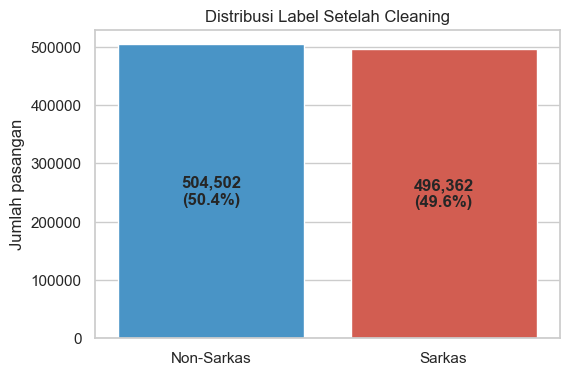

In [5]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="label_name", hue="label_name", palette=PALETTE, legend=False)
for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{int(h):,}\n({h / len(df):.1%})", (p.get_x() + p.get_width() / 2, h / 2),
                ha="center", va="center", fontweight="bold")
plt.title("Distribusi Label Setelah Cleaning")
plt.xlabel("")
plt.ylabel("Jumlah pasangan")
save_fig("01_label_distribution")
plt.show()

#### Insight
Datanya hampir seimbang: 504.502 bukan sarkas dan 496.362 sarkas (49,59% sarkas). Proporsi sarkas sedikit di bawah 50% karena artefak `/s` yang dibuang hampir semuanya berlabel sarkas.

Karena seimbang, tidak perlu teknik penyeimbangan data seperti oversampling. Accuracy juga tetap bisa dipakai, tetapi tetap dilaporkan bersama precision, recall, F1, dan macro-F1.

### 4.2 Distribusi Panjang Karakter dan Jumlah Kata per Komentar

Grafik ini membandingkan panjang comment sarkas dan bukan sarkas, dalam jumlah karakter dan jumlah kata. Supaya bentuknya terlihat, comment di atas 200 karakter atau 40 kata tidak ditampilkan.

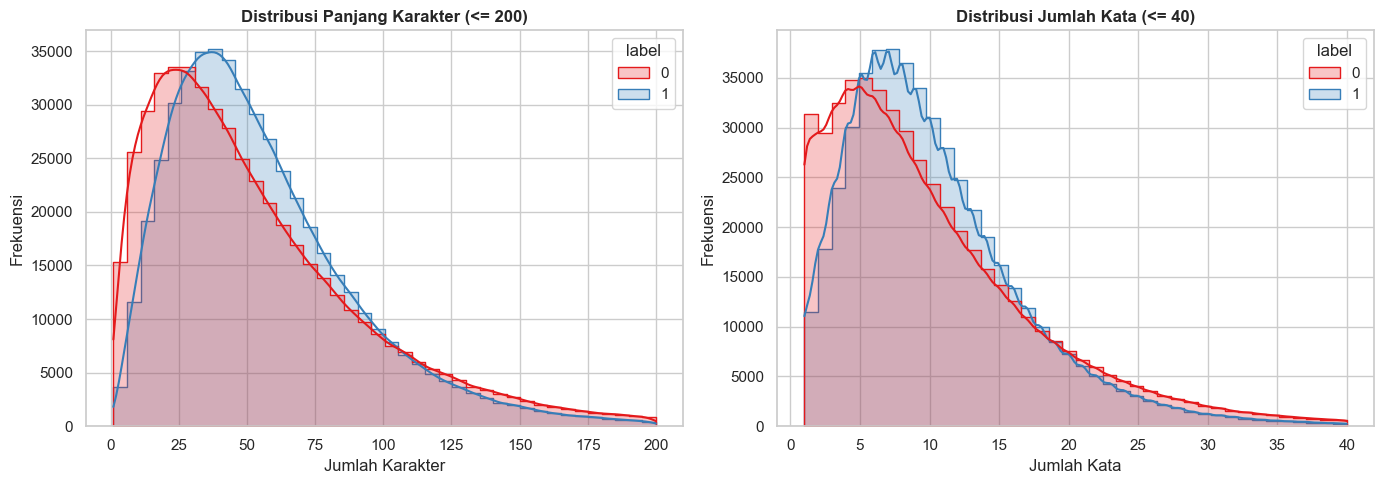

In [6]:
df['char_length'] = df['comment'].astype(str).apply(len)
df['word_count'] = df['comment'].astype(str).apply(lambda x: len(x.split()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df[df['char_length'] <= 200], x='char_length', hue='label', 
             kde=True, bins=40, palette='Set1', ax=axes[0], element='step')
axes[0].set_title('Distribusi Panjang Karakter (<= 200)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jumlah Karakter')
axes[0].set_ylabel('Frekuensi')

sns.histplot(data=df[df['word_count'] <= 40], x='word_count', hue='label', 
             kde=True, bins=40, palette='Set1', ax=axes[1], element='step')
axes[1].set_title('Distribusi Jumlah Kata (<= 40)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Jumlah Kata')
axes[1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

#### Insight
Kedua grafik condong ke kiri dengan ekor panjang ke kanan. Sebagian besar comment Reddit pendek, dan median panjangnya 9 kata untuk sarkas maupun bukan sarkas (lihat tabel di bagian 6.3).

Kurva sarkas dan bukan sarkas hampir menumpuk sempurna. Jadi panjang comment tidak bisa dipakai untuk membedakan sarkas. Ada sarkas yang sangat pendek seperti "Brilliant." dan ada juga yang panjang.

Panjang input model dihitung dalam token dari pasangan parent dan comment, bukan dari jumlah kata comment saja. Batas 256 token dicek di bagian 7.1.

### 4.3 Distribusi Top 15 Subreddit Paling Banyak Komentar

Grafik ini menunjukkan 15 subreddit dengan comment terbanyak, dipisah antara sarkas dan bukan sarkas.

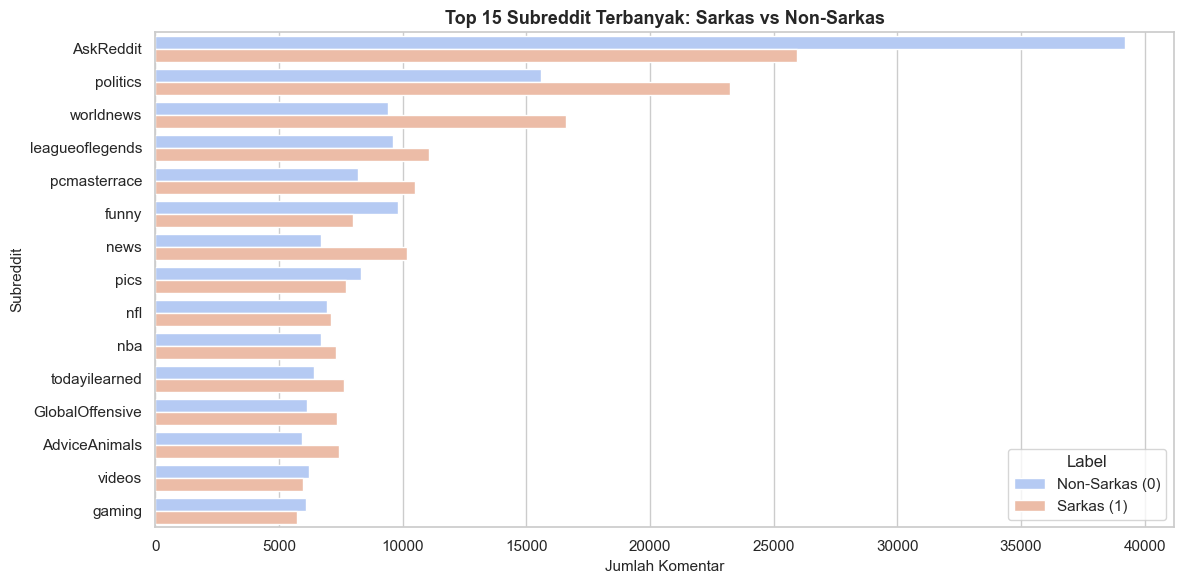

In [7]:
top_subreddits = df['subreddit'].value_counts().nlargest(15).index
df_top_sub = df[df['subreddit'].isin(top_subreddits)]

plt.figure(figsize=(12, 6))
sns.countplot(y='subreddit', hue='label', data=df_top_sub, 
              order=top_subreddits, palette='coolwarm')
plt.title('Top 15 Subreddit Terbanyak: Sarkas vs Non-Sarkas', fontsize=13, fontweight='bold')
plt.xlabel('Jumlah Komentar', fontsize=11)
plt.ylabel('Subreddit', fontsize=11)
plt.legend(title='Label', labels=['Non-Sarkas (0)', 'Sarkas (1)'])
plt.tight_layout()
plt.show()

#### Insight
Comment paling banyak berasal dari subreddit diskusi umum (AskReddit, politics, worldnews, news) dan subreddit hobi atau game (leagueoflegends, pcmasterrace, nfl, nba).

Proporsi sarkas berbeda cukup jauh antar-subreddit. Di politics, worldnews, dan news, comment sarkas jauh lebih banyak dari yang bukan sarkas, misalnya worldnews sekitar 16.600 sarkas dibanding 9.400 bukan sarkas. Sebaliknya di AskReddit, comment bukan sarkas lebih banyak (sekitar 39.000 dibanding 26.000), begitu juga di funny dan pics.

Artinya topik ikut memengaruhi seberapa sering orang bersarkasme, terutama topik politik dan berita. Penelitian ini tidak memakai nama subreddit sebagai input model, karena fokusnya teks comment dan parent saja.

### 4.4 Distribusi Skor Reddit (score) Berdasarkan Label

Grafik ini membandingkan skor comment (upvote dikurangi downvote) antara sarkas dan bukan sarkas, dibatasi di rentang -10 sampai 50 supaya kotaknya terlihat.

C:\Users\User\AppData\Local\Temp\ipykernel_19596\1456893267.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label', y='score', data=df[(df['score'] >= -10) & (df['score'] <= 50)], palette='Pastel1')


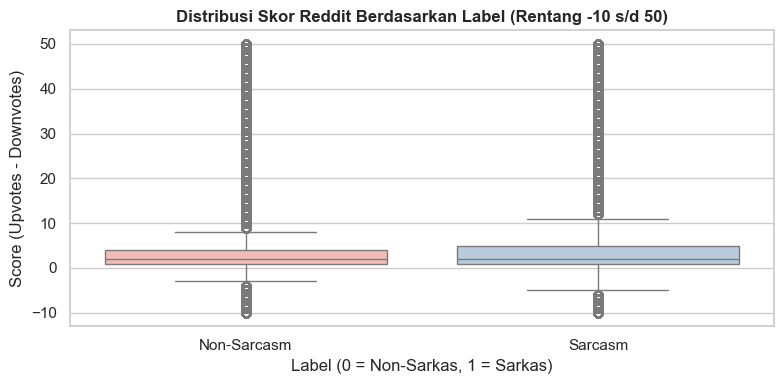

In [8]:
plt.figure(figsize=(8, 4))

sns.boxplot(x='label', y='score', data=df[(df['score'] >= -10) & (df['score'] <= 50)], palette='Pastel1')
plt.title('Distribusi Skor Reddit Berdasarkan Label (Rentang -10 s/d 50)', fontsize=12, fontweight='bold')
plt.xlabel('Label (0 = Non-Sarkas, 1 = Sarkas)')
plt.ylabel('Score (Upvotes - Downvotes)')
plt.xticks([0, 1], ['Non-Sarcasm', 'Sarcasm'])
plt.tight_layout()
plt.show()

#### Insight
Kotak kedua kelas hampir sama. Median skornya sama-sama 2 (lihat tabel di bagian 4.5), jadi comment sarkas tidak lebih sering di-downvote dibanding comment biasa. Skor tidak bisa dipakai untuk membedakan sarkas.

### 4.5 Popularitas Komentar Berdasarkan Sarkasme

Bagian ini melihat apakah comment sarkas lebih populer. Donut chart menunjukkan jumlah total skor tiap kelas, lalu tabel di bawahnya menunjukkan median dan sebaran skornya.

In [9]:
# Converting the scores into numpy array
sarcasm_score = np.array(df.loc[df['label'] == 1]['score'])
neutral_score = np.array(df.loc[df['label'] == 0]['score'])

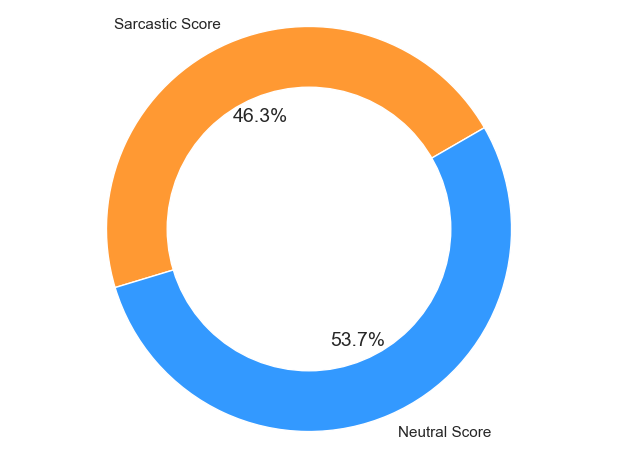

,count,mean,std,min,25%,50%,75%,max,% skor > 0,Jumlah skor
label_name,,,,,,,,,,
Non-Sarkas,504502.0,7.37,56.04,-298.0,1.0,2.0,4.0,5818.0,91.06,3720091
Sarkas,496362.0,6.47,39.55,-507.0,1.0,2.0,5.0,9070.0,83.97,3212073


In [10]:
# Jumlah skor per kelas, dihitung langsung dari data
labels = ['Sarcastic Score', 'Neutral Score']
sizes = [df.loc[df['label'] == 1, 'score'].sum(), df.loc[df['label'] == 0, 'score'].sum()]

colors = ['#FF9933', '#3399FF']
plt.rcParams.update({'font.size': 14})
fig1, ax1 = plt.subplots()
ax1.pie(sizes, colors=colors, labels=labels, autopct='%1.1f%%', startangle=30)
ax1.add_artist(plt.Circle((0, 0), 0.70, fc='white'))      # lubang tengah (donut chart)
ax1.axis('equal')
plt.tight_layout()
plt.show()
plt.rcParams.update({'font.size': 10})

# Pembanding yang lebih adil: median dan sebaran skor per kelas
score_summary = df.groupby("label_name")["score"].describe(percentiles=[0.25, 0.5, 0.75])
score_summary["% skor > 0"] = df.groupby("label_name")["score"].apply(lambda s: (s > 0).mean() * 100)
score_summary["Jumlah skor"] = df.groupby("label_name")["score"].sum()
display(score_summary.round(2))

Jumlah total skor mudah tertipu oleh beberapa comment yang skornya sangat besar, karena skor maksimum bisa ribuan. Karena itu perbandingan yang lebih adil dilihat dari median dan persentil di tabel.

#### Insight
Total skor comment bukan sarkas (3.720.091) lebih besar dari comment sarkas (3.212.073), tetapi angka ini terpengaruh nilai ekstrem. Median keduanya sama, yaitu 2, dan kuartil atasnya hampir sama (4 dan 5).

Perbedaan yang terlihat ada di persentase skor positif: 91,06% comment bukan sarkas punya skor di atas 0, sedangkan comment sarkas 83,97%. Jadi comment sarkas sedikit lebih sering kurang disukai, tetapi perbedaannya kecil dan skor tetap bukan petunjuk yang kuat.

### 4.6 Sarkasme Berdasarkan Hari dalam Seminggu

Bagian ini melihat apakah proporsi sarkas berubah menurut hari posting.

In [11]:
# Salin dataframe agar data asli tetap aman
analysis_df = df.copy()

# Konversi tanggal secara lebih aman
analysis_df["created_utc"] = pd.to_datetime(
    analysis_df["created_utc"],
    dayfirst=True,
    errors="coerce"
)

# Hapus baris dengan tanggal atau label yang tidak valid
analysis_df = analysis_df.dropna(
    subset=["created_utc", "label"]
).copy()

# Ekstraksi nama hari
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

analysis_df["day_of_week"] = pd.Categorical(
    analysis_df["created_utc"].dt.day_name(),
    categories=day_order,
    ordered=True
)

# Statistik per hari
daily_summary = (
    analysis_df
    .groupby("day_of_week", observed=False)
    .agg(
        total_comments=("label", "size"),
        sarcastic_comments=("label", "sum")
    )
    .reset_index()
)

daily_summary["non_sarcastic_comments"] = (
    daily_summary["total_comments"] -
    daily_summary["sarcastic_comments"]
)

# Persentase sarcastic dari seluruh komentar pada hari tersebut
daily_summary["sarcasm_rate"] = (
    daily_summary["sarcastic_comments"] /
    daily_summary["total_comments"] * 100
)

# Persentase kontribusi tiap hari terhadap seluruh komentar sarcastic
total_sarcastic = daily_summary["sarcastic_comments"].sum()

daily_summary["share_of_all_sarcastic"] = (
    daily_summary["sarcastic_comments"] /
    total_sarcastic * 100
)

display(daily_summary.round(2))

C:\Users\User\AppData\Local\Temp\ipykernel_19596\3248163133.py:5: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  analysis_df["created_utc"] = pd.to_datetime(


,day_of_week,total_comments,sarcastic_comments,non_sarcastic_comments,sarcasm_rate,share_of_all_sarcastic
0,Monday,144955,72145,72810,49.77,14.53
1,Tuesday,152050,76288,75762,50.17,15.37
2,Wednesday,154970,77418,77552,49.96,15.60
3,Thursday,153910,76891,77019,49.96,15.49
4,Friday,148373,73425,74948,49.49,14.79
5,Saturday,121358,58889,62469,48.53,11.86
6,Sunday,125248,61306,63942,48.95,12.35


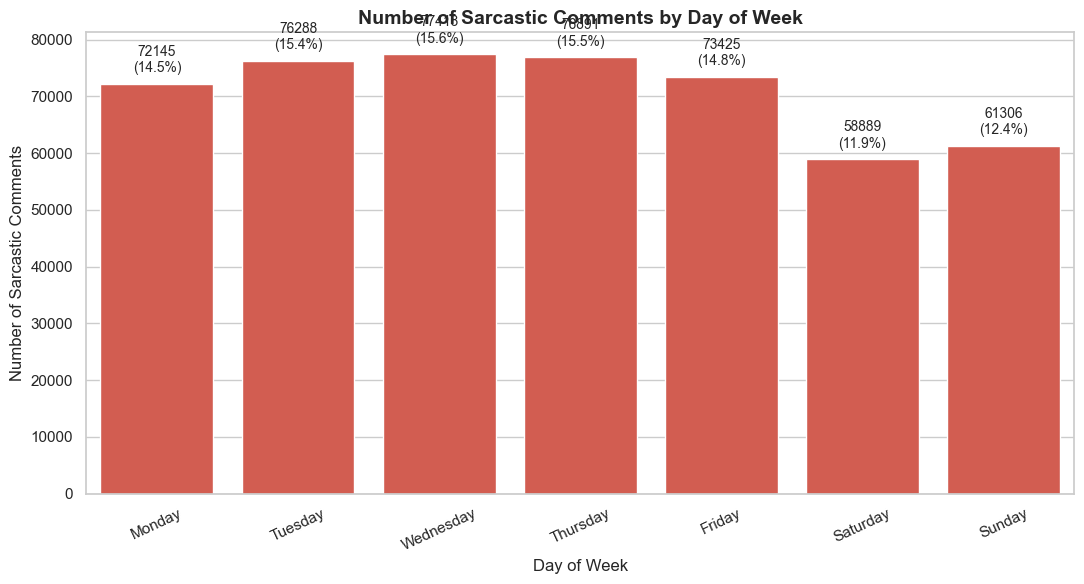

In [12]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=daily_summary,
    x="day_of_week",
    y="sarcastic_comments",
    order=day_order,
    color="#E74C3C"
)

plt.title(
    "Number of Sarcastic Comments by Day of Week",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Day of Week")
plt.ylabel("Number of Sarcastic Comments")
plt.xticks(rotation=25)

# Tambahkan jumlah dan persentase kontribusi
for i, row in daily_summary.iterrows():
    ax.text(
        i,
        row["sarcastic_comments"] + daily_summary["sarcastic_comments"].max() * 0.02,
        f'{int(row["sarcastic_comments"])}\n'
        f'({row["share_of_all_sarcastic"]:.1f}%)',
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

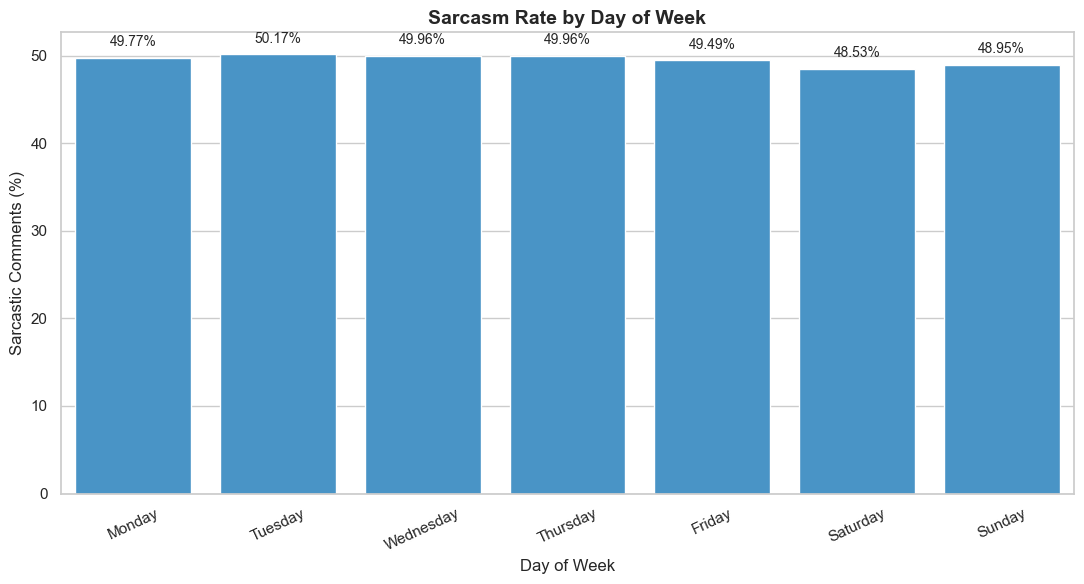

In [13]:
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=daily_summary,
    x="day_of_week",
    y="sarcasm_rate",
    order=day_order,
    color="#3498DB"
)

plt.title(
    "Sarcasm Rate by Day of Week",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Day of Week")
plt.ylabel("Sarcastic Comments (%)")
plt.xticks(rotation=25)

for i, row in daily_summary.iterrows():
    ax.text(
        i,
        row["sarcasm_rate"] + daily_summary["sarcasm_rate"].max() * 0.02,
        f'{row["sarcasm_rate"]:.2f}%',
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

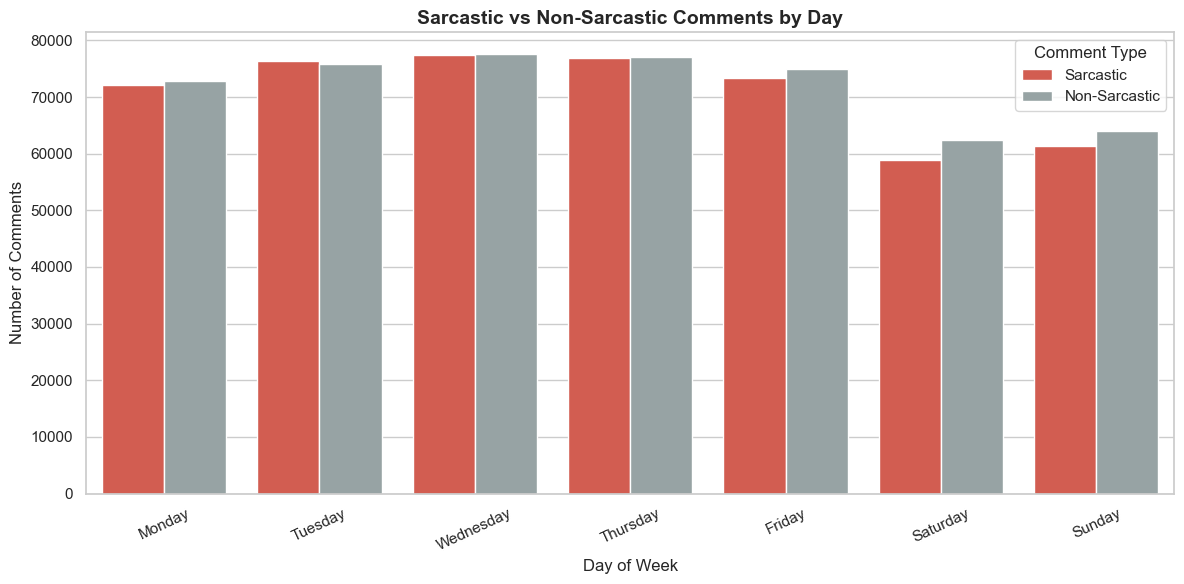

In [14]:
plot_df = daily_summary[
    [
        "day_of_week",
        "sarcastic_comments",
        "non_sarcastic_comments"
    ]
].melt(
    id_vars="day_of_week",
    var_name="comment_type",
    value_name="count"
)

plot_df["comment_type"] = plot_df["comment_type"].replace({
    "sarcastic_comments": "Sarcastic",
    "non_sarcastic_comments": "Non-Sarcastic"
})

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=plot_df,
    x="day_of_week",
    y="count",
    hue="comment_type",
    order=day_order,
    palette={
        "Sarcastic": "#E74C3C",
        "Non-Sarcastic": "#95A5A6"
    }
)

plt.title(
    "Sarcastic vs Non-Sarcastic Comments by Day",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Day of Week")
plt.ylabel("Number of Comments")
plt.xticks(rotation=25)
plt.legend(title="Comment Type")

plt.tight_layout()
plt.show()

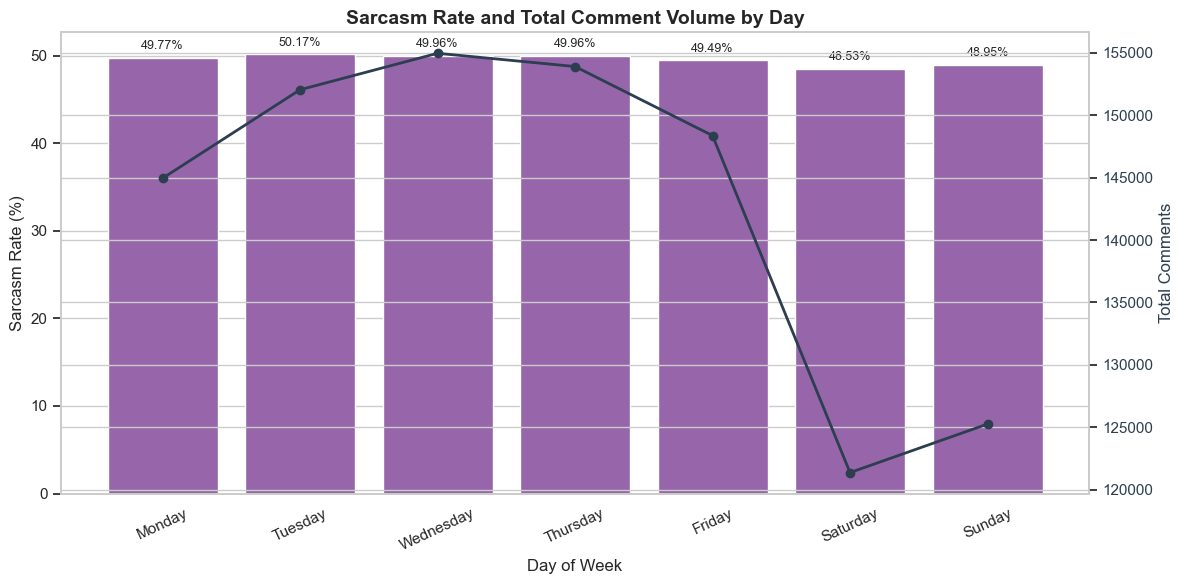

In [15]:
fig, ax1 = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=daily_summary,
    x="day_of_week",
    y="sarcasm_rate",
    order=day_order,
    color="#9B59B6",
    ax=ax1
)

ax1.set_title(
    "Sarcasm Rate and Total Comment Volume by Day",
    fontsize=14,
    fontweight="bold"
)
ax1.set_xlabel("Day of Week")
ax1.set_ylabel("Sarcasm Rate (%)")
ax1.tick_params(axis="x", rotation=25)

for i, row in daily_summary.iterrows():
    ax1.text(
        i,
        row["sarcasm_rate"] + daily_summary["sarcasm_rate"].max() * 0.02,
        f'{row["sarcasm_rate"]:.2f}%',
        ha="center",
        fontsize=9
    )

# Sumbu kedua untuk jumlah komentar
ax2 = ax1.twinx()

ax2.plot(
    range(len(daily_summary)),
    daily_summary["total_comments"],
    color="#2C3E50",
    marker="o",
    linewidth=2,
    label="Total Comments"
)

ax2.set_ylabel("Total Comments", color="#2C3E50")
ax2.tick_params(axis="y", labelcolor="#2C3E50")

plt.tight_layout()
plt.show()

In [16]:
highest_rate_day = daily_summary.loc[
    daily_summary["sarcasm_rate"].idxmax()
]

lowest_rate_day = daily_summary.loc[
    daily_summary["sarcasm_rate"].idxmin()
]

print(
    f"Hari dengan sarcasm rate tertinggi: "
    f"{highest_rate_day['day_of_week']} "
    f"({highest_rate_day['sarcasm_rate']:.2f}%)"
)

print(
    f"Hari dengan sarcasm rate terendah: "
    f"{lowest_rate_day['day_of_week']} "
    f"({lowest_rate_day['sarcasm_rate']:.2f}%)"
)

Hari dengan sarcasm rate tertinggi: Tuesday (50.17%)
Hari dengan sarcasm rate terendah: Saturday (48.53%)


#### Insight
Proporsi sarkas hampir sama setiap hari, sekitar setengah dari seluruh comment. Yang tertinggi Selasa (50,17%) dan yang terendah Sabtu (48,53%), selisihnya hanya 1,6 poin. Jadi hari posting bukan faktor penentu sarkasme.

Perbedaan yang lebih jelas ada di jumlah comment. Hari kerja punya sekitar 145.000 sampai 155.000 comment per hari, sedangkan Sabtu dan Minggu sekitar 121.000 sampai 125.000.

Perlu diingat, dataset ini sengaja diseimbangkan, jadi pola waktu ini tidak menggambarkan seberapa sering orang bersarkasme di Reddit yang sebenarnya.

## 5. Analisis Leksikal

Bagian ini melihat kata dan rangkaian kata yang sering muncul di comment sarkas dan bukan sarkas. Masing-masing diambil sampel 50.000 comment.

### 5.1 WordCloud

WordCloud menampilkan kata yang paling sering muncul. Makin besar tulisannya, makin sering kata itu muncul. Kata umum seperti "the" dan "and" (stopword) tidak ditampilkan.

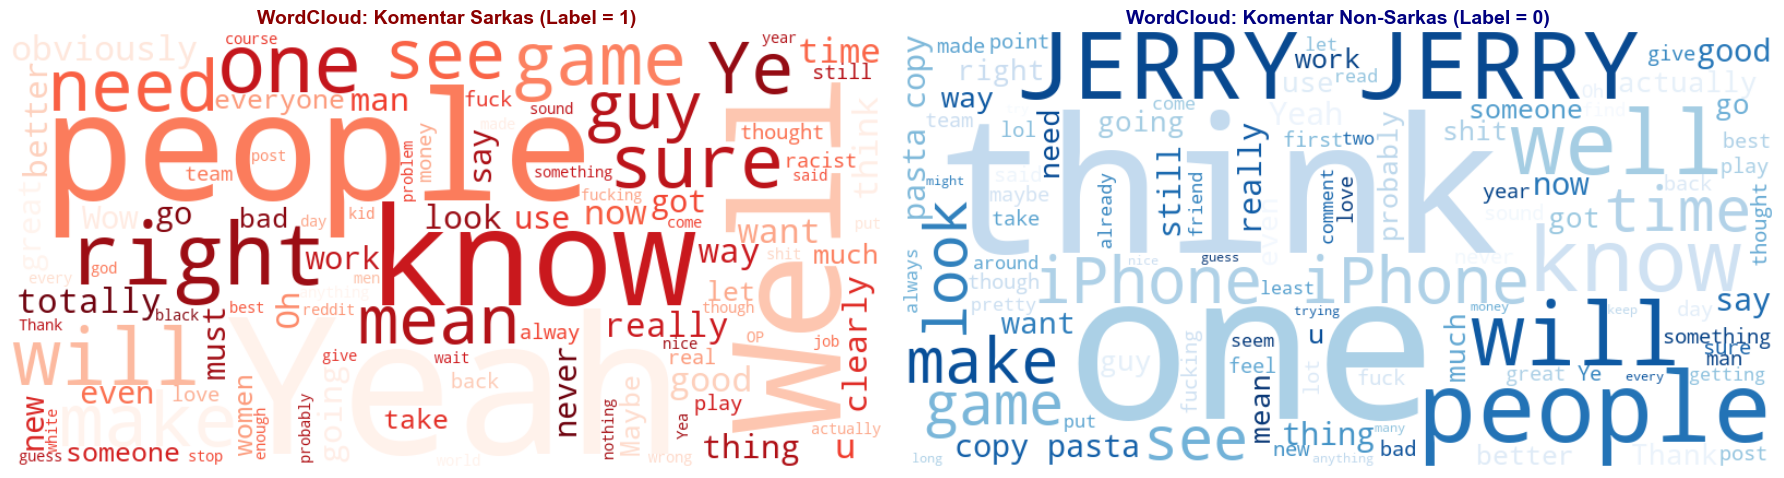

In [17]:
sample_sarcasm = df[df['label'] == 1]['comment'].sample(50000, random_state=42).astype(str)
sample_non_sarcasm = df[df['label'] == 0]['comment'].sample(50000, random_state=42).astype(str)

text_sarcasm = " ".join(sample_sarcasm)
text_non_sarcasm = " ".join(sample_non_sarcasm)

stopwords = set(STOPWORDS)

wc_sarcasm = WordCloud(width=800, height=400, background_color='white',
                       stopwords=stopwords, max_words=100, colormap='Reds').generate(text_sarcasm)

wc_non_sarcasm = WordCloud(width=800, height=400, background_color='white',
                           stopwords=stopwords, max_words=100, colormap='Blues').generate(text_non_sarcasm)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

axes[0].imshow(wc_sarcasm, interpolation='bilinear')
axes[0].set_title('WordCloud: Komentar Sarkas (Label = 1)', fontsize=14, fontweight='bold', color='darkred')
axes[0].axis('off')

axes[1].imshow(wc_non_sarcasm, interpolation='bilinear')
axes[1].set_title('WordCloud: Komentar Non-Sarkas (Label = 0)', fontsize=14, fontweight='bold', color='navy')
axes[1].axis('off')

plt.tight_layout()
plt.show()

#### Insight
Di comment sarkas banyak muncul kata yang bernada setuju atau yakin secara berlebihan, seperti "Yeah", "sure", "right", "obviously", "totally", dan "clearly". Kata-kata ini sering dipakai untuk menyindir, misalnya "Yeah, because that totally works".

Di comment bukan sarkas, kata yang besar justru "JERRY" dan "iPhone", yang berasal dari comment spam yang diulang-ulang (dibahas di bagian 5.2). Selain itu muncul kata umum seperti "think", "one", "people", dan "time".

Banyak kata yang muncul besar di kedua kelas, misalnya "people", "know", "well", dan "game". Jadi frekuensi kata saja tidak cukup untuk membedakan sarkas, dan model perlu memahami konteks kalimat.

### 5.2 Bi-gram dan Tri-gram

Bi-gram adalah pasangan 2 kata yang berurutan, dan tri-gram adalah rangkaian 3 kata. Grafik ini menampilkan 10 rangkaian yang paling sering muncul di setiap kelas.

C:\Users\User\AppData\Local\Temp\ipykernel_19596\3508795767.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='count', y='ngram', data=top_bi_sarcasm, ax=axes[0, 0], palette='Reds_r')
C:\Users\User\AppData\Local\Temp\ipykernel_19596\3508795767.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='count', y='ngram', data=top_bi_non_sarcasm, ax=axes[0, 1], palette='Blues_r')
C:\Users\User\AppData\Local\Temp\ipykernel_19596\3508795767.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='count', y='ngram', data=top_tri_sarcasm, ax=axes

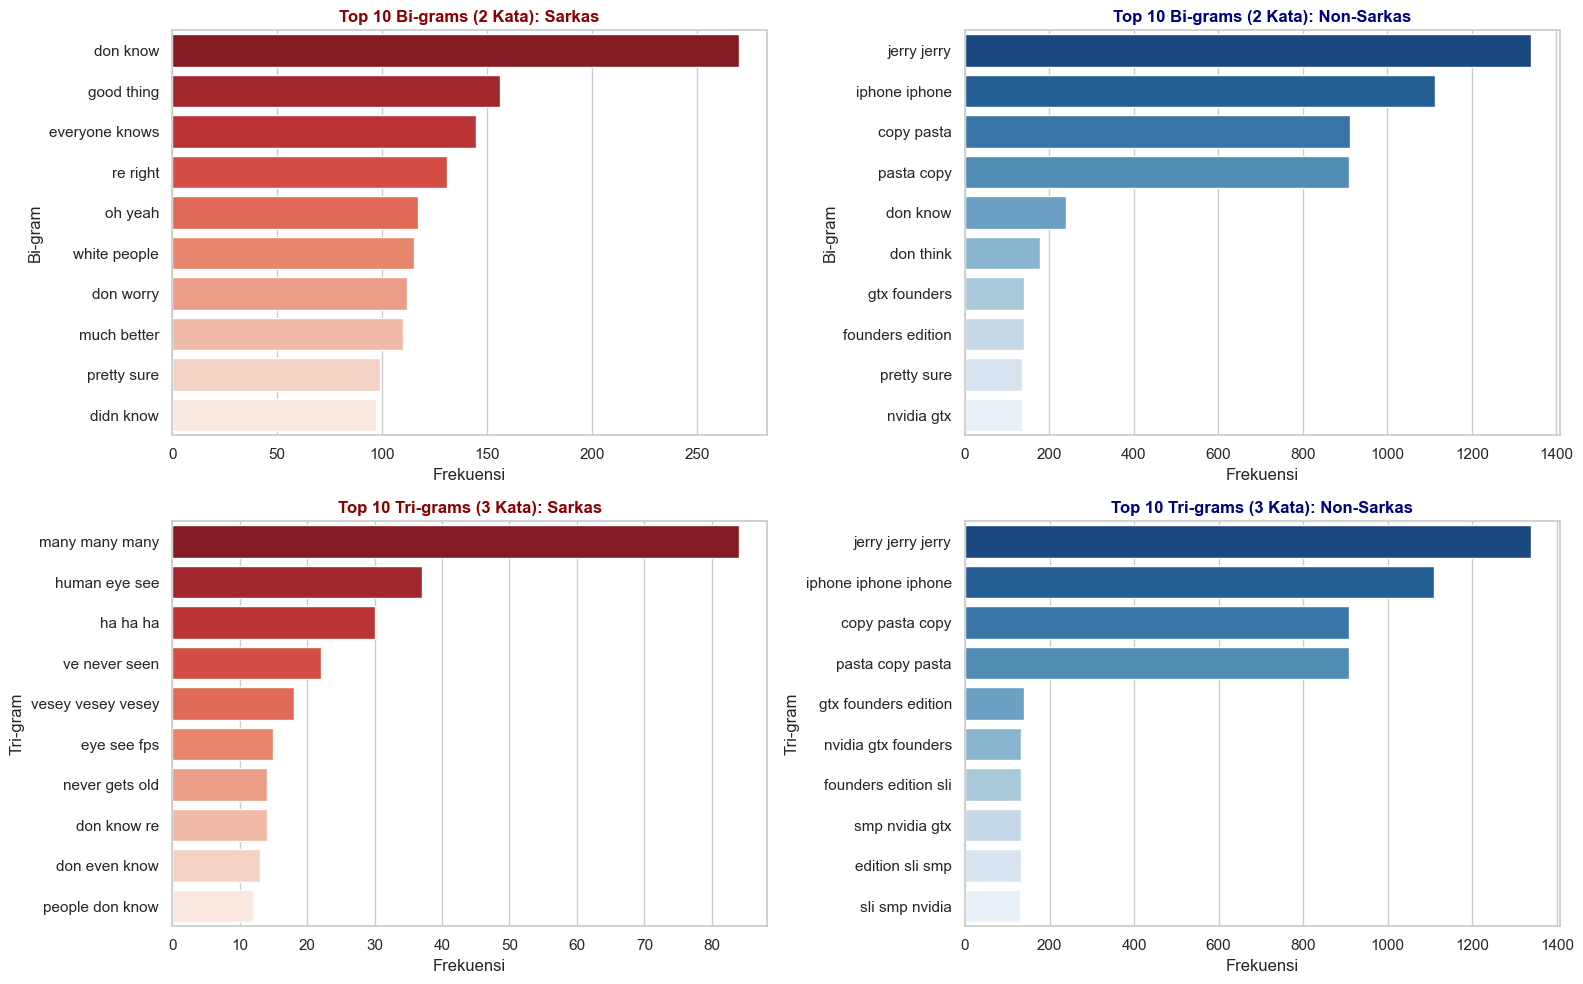

In [18]:
# 1. Fungsi ekstraksi N-Gram murni Python (tanpa dependency scipy/sklearn)
def get_top_ngrams_native(corpus, n=2, top_k=10, stopwords=STOPWORDS):
    counter = Counter()
    for text in corpus:
        # Tokenisasi kata (hanya huruf, huruf kecil, abaikan stopwords)
        tokens = [w for w in re.findall(r'\b[a-zA-Z]+\b', str(text).lower()) 
                  if w not in stopwords and len(w) > 1]
        
        # Bentuk pasangan n-gram
        if len(tokens) >= n:
            ngrams = [' '.join(tokens[i:i+n]) for i in range(len(tokens) - n + 1)]
            counter.update(ngrams)
            
    return pd.DataFrame(counter.most_common(top_k), columns=['ngram', 'count'])

# 2. Ambil sampel 50.000 data per kelas
sample_sarcasm = df[df['label'] == 1]['comment'].sample(50000, random_state=42).astype(str)
sample_non_sarcasm = df[df['label'] == 0]['comment'].sample(50000, random_state=42).astype(str)

# 3. Ekstraksi Top 10 Bi-grams (2 kata) & Tri-grams (3 kata)
top_bi_sarcasm = get_top_ngrams_native(sample_sarcasm, n=2, top_k=10)
top_bi_non_sarcasm = get_top_ngrams_native(sample_non_sarcasm, n=2, top_k=10)

top_tri_sarcasm = get_top_ngrams_native(sample_sarcasm, n=3, top_k=10)
top_tri_non_sarcasm = get_top_ngrams_native(sample_non_sarcasm, n=3, top_k=10)

# 4. Visualisasi Grid 2x2
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Barplot Bi-gram Sarkas
sns.barplot(x='count', y='ngram', data=top_bi_sarcasm, ax=axes[0, 0], palette='Reds_r')
axes[0, 0].set_title('Top 10 Bi-grams (2 Kata): Sarkas', fontsize=12, fontweight='bold', color='darkred')
axes[0, 0].set_xlabel('Frekuensi')
axes[0, 0].set_ylabel('Bi-gram')

# Barplot Bi-gram Non-Sarkas
sns.barplot(x='count', y='ngram', data=top_bi_non_sarcasm, ax=axes[0, 1], palette='Blues_r')
axes[0, 1].set_title('Top 10 Bi-grams (2 Kata): Non-Sarkas', fontsize=12, fontweight='bold', color='navy')
axes[0, 1].set_xlabel('Frekuensi')
axes[0, 1].set_ylabel('Bi-gram')

# Barplot Tri-gram Sarkas
sns.barplot(x='count', y='ngram', data=top_tri_sarcasm, ax=axes[1, 0], palette='Reds_r')
axes[1, 0].set_title('Top 10 Tri-grams (3 Kata): Sarkas', fontsize=12, fontweight='bold', color='darkred')
axes[1, 0].set_xlabel('Frekuensi')
axes[1, 0].set_ylabel('Tri-gram')

# Barplot Tri-gram Non-Sarkas
sns.barplot(x='count', y='ngram', data=top_tri_non_sarcasm, ax=axes[1, 1], palette='Blues_r')
axes[1, 1].set_title('Top 10 Tri-grams (3 Kata): Non-Sarkas', fontsize=12, fontweight='bold', color='navy')
axes[1, 1].set_xlabel('Frekuensi')
axes[1, 1].set_ylabel('Tri-gram')

plt.tight_layout()
plt.show()

#### Insight
Bi-gram sarkas banyak berisi ungkapan yang khas untuk menyindir, seperti "good thing", "everyone knows", "oh yeah", "much better", "pretty sure", dan "don worry". Tri-gram sarkas juga memuat ungkapan seperti "never gets old" dan "ha ha ha", serta lelucon Reddit yang sering diulang seperti "human eye see" (dari "the human eye can't see more than 30 fps").

Bi-gram dan tri-gram bukan sarkas didominasi spam yang diulang-ulang, seperti "jerry jerry jerry", "iphone iphone iphone", "copy pasta copy", dan "gtx founders edition sli". Jumlahnya sampai lebih dari 1.000 kali, jauh lebih banyak dari n-gram sarkas teratas (sekitar 270 kali). Spam seperti ini membuat daftar n-gram tidak menggambarkan bahasa sehari-hari.

Beberapa rangkaian seperti "don know" dan "pretty sure" muncul di kedua kelas. Jadi n-gram memberi sedikit petunjuk, tetapi tidak cukup untuk membedakan sarkas dengan andal.

## 6. Analisis Konteks Comment dan Parent

Bagian ini melihat hubungan antara comment dan parent comment, karena sarkasme sering baru terlihat jelas kalau tahu comment itu membalas apa. Hubungannya dilihat dari tiga sisi:
- panjang: apakah comment merupakan balasan singkat untuk parent yang panjang,
- kemiripan kata: apakah comment mengulang kata-kata di parent,
- kontras sentimen: apakah parent bernada negatif dibalas comment yang terdengar positif.

Kecuali bagian 6.1, fitur dihitung dari sampel 25.000 pasangan per label.

### 6.1 Panjang Comment Sarkas dibanding Parent

Grafik ini membandingkan panjang comment sarkas dengan panjang parent yang dibalasnya, memakai semua comment sarkas.

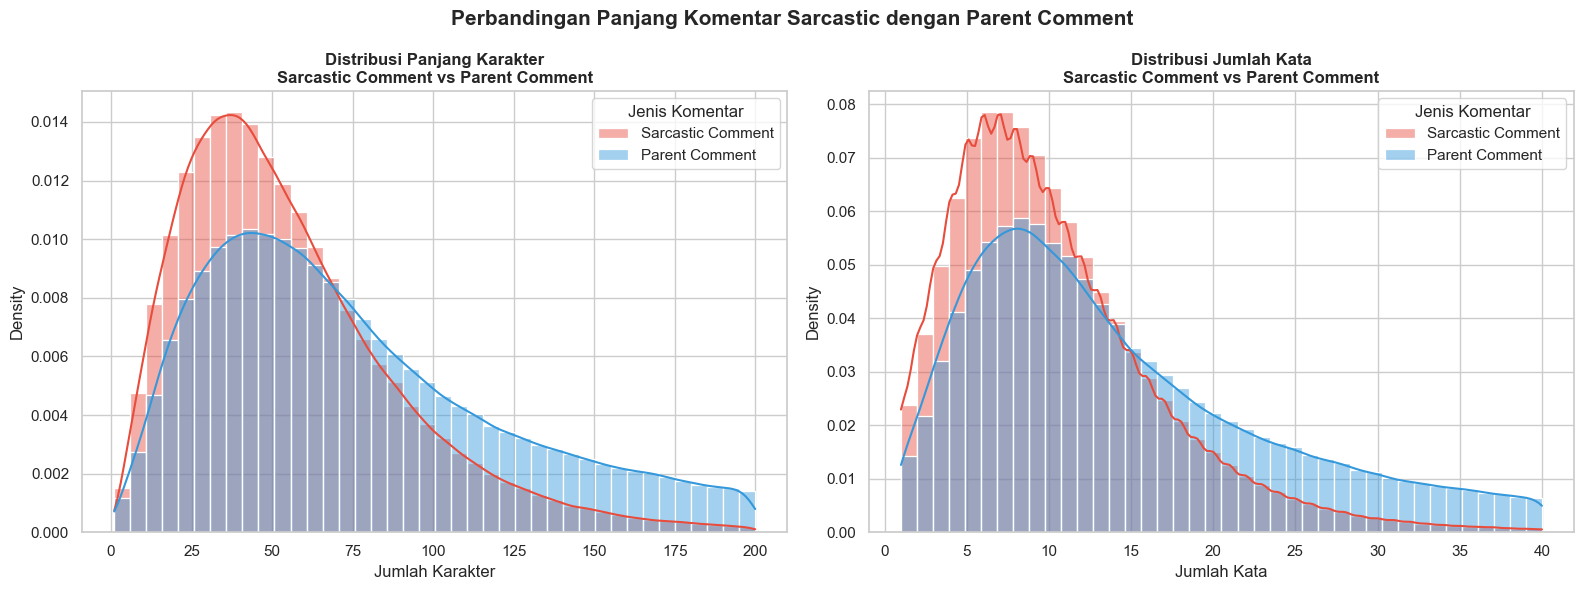

In [19]:
# Ambil hanya komentar sarcastic
sarcastic_df = df[df["label"] == 1].copy()

# Pastikan nilai kosong tidak menghasilkan error
sarcastic_df["comment"] = sarcastic_df["comment"].fillna("").astype(str)
sarcastic_df["parent_comment"] = (
    sarcastic_df["parent_comment"]
    .fillna("")
    .astype(str)
)

# Hitung panjang berdasarkan karakter
sarcastic_df["comment_char_length"] = sarcastic_df["comment"].str.len()
sarcastic_df["parent_char_length"] = sarcastic_df["parent_comment"].str.len()

# Hitung panjang berdasarkan jumlah kata
sarcastic_df["comment_word_count"] = (
    sarcastic_df["comment"].str.split().str.len()
)

sarcastic_df["parent_word_count"] = (
    sarcastic_df["parent_comment"].str.split().str.len()
)

# Batasi nilai ekstrem agar pola distribusi lebih mudah terlihat
char_limit = 200
word_limit = 40

comment_char = sarcastic_df[
    sarcastic_df["comment_char_length"] <= char_limit
]["comment_char_length"]

parent_char = sarcastic_df[
    sarcastic_df["parent_char_length"] <= char_limit
]["parent_char_length"]

comment_words = sarcastic_df[
    sarcastic_df["comment_word_count"] <= word_limit
]["comment_word_count"]

parent_words = sarcastic_df[
    sarcastic_df["parent_word_count"] <= word_limit
]["parent_word_count"]

# Pengaturan visual
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Visualisasi jumlah karakter
sns.histplot(
    comment_char,
    bins=40,
    kde=True,
    stat="density",
    color="#E74C3C",
    alpha=0.45,
    edgecolor="white",
    label="Sarcastic Comment",
    ax=axes[0]
)

sns.histplot(
    parent_char,
    bins=40,
    kde=True,
    stat="density",
    color="#3498DB",
    alpha=0.45,
    edgecolor="white",
    label="Parent Comment",
    ax=axes[0]
)

axes[0].set_title(
    "Distribusi Panjang Karakter\nSarcastic Comment vs Parent Comment",
    fontsize=12,
    fontweight="bold"
)
axes[0].set_xlabel("Jumlah Karakter")
axes[0].set_ylabel("Density")
axes[0].legend(title="Jenis Komentar")

# Visualisasi jumlah kata
sns.histplot(
    comment_words,
    bins=40,
    kde=True,
    stat="density",
    color="#E74C3C",
    alpha=0.45,
    edgecolor="white",
    label="Sarcastic Comment",
    ax=axes[1]
)

sns.histplot(
    parent_words,
    bins=40,
    kde=True,
    stat="density",
    color="#3498DB",
    alpha=0.45,
    edgecolor="white",
    label="Parent Comment",
    ax=axes[1]
)

axes[1].set_title(
    "Distribusi Jumlah Kata\nSarcastic Comment vs Parent Comment",
    fontsize=12,
    fontweight="bold"
)
axes[1].set_xlabel("Jumlah Kata")
axes[1].set_ylabel("Density")
axes[1].legend(title="Jenis Komentar")

plt.suptitle(
    "Perbandingan Panjang Komentar Sarcastic dengan Parent Comment",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

#### Insight
Comment sarkas umumnya lebih pendek dari parent-nya. Kurva comment sarkas memuncak di sekitar 35 sampai 40 karakter atau 6 sampai 8 kata, sedangkan kurva parent lebih landai dan ekornya jauh lebih panjang. Di tabel bagian 6.3, median comment sarkas 9 kata dan median parent-nya 14 kata.

Ini sesuai dengan cara orang bersarkasme di forum: parent memberi cerita atau pernyataan, lalu sarkasme disampaikan lewat balasan singkat. Karena comment-nya pendek, maknanya sering bergantung pada parent.

Kedua kurva tetap tumpang tindih cukup banyak, jadi panjang saja tidak cukup untuk mengenali sarkasme.

### 6.2 Fitur Pasangan Comment dan Parent

Bagian ini menghitung beberapa fitur sederhana untuk setiap pasangan comment dan parent. Fitur ini hanya untuk EDA dan tidak dipakai sebagai input model.

In [20]:
ctx = df.groupby("label", group_keys=False).sample(25_000, random_state=SEED).reset_index(drop=True)

# 1) Panjang dalam kata (dihitung dari kunci tanpa tanda baca, supaya "great!!!" tetap dihitung 1 kata)
ctx["len_comment"] = ctx["comment_key"].str.split().str.len()
ctx["len_parent"] = ctx["parent_key"].str.split().str.len()
ctx["len_ratio"] = ctx["len_comment"] / ctx["len_parent"]

# 2) Kemiripan kata: cosine TF-IDF per pasangan + proporsi kata comment yang ada di parent
tfidf = TfidfVectorizer(min_df=2).fit(pd.concat([ctx["comment_clean"], ctx["parent_clean"]]))
C = tfidf.transform(ctx["comment_clean"])
P = tfidf.transform(ctx["parent_clean"])
ctx["cosine_sim"] = np.asarray(C.multiply(P).sum(axis=1)).ravel()   # baris sudah ter-normalisasi L2

def overlap(c, p):
    c, p = set(c.split()), set(p.split())
    return len(c & p) / len(c)
ctx["word_overlap"] = [overlap(c, p) for c, p in zip(ctx["comment_key"], ctx["parent_key"])]

# 3) Sentimen VADER dari teks asli (VADER memakai tanda baca dan kapital)
vader = SentimentIntensityAnalyzer()
ctx["sent_comment"] = [vader.polarity_scores(t)["compound"] for t in ctx["comment"]]
ctx["sent_parent"] = [vader.polarity_scores(t)["compound"] for t in ctx["parent_comment"]]
ctx["sent_gap"] = (ctx["sent_comment"] - ctx["sent_parent"]).abs()

#### Penjelasan Fitur

| Fitur | Aspek | Cara hitung | Rentang | Cara membaca |
|---|---|---|---|---|
| `len_comment` | Panjang | Jumlah kata comment (tanpa tanda baca) | ≥ 1 | Makin besar, comment makin panjang |
| `len_parent` | Panjang | Jumlah kata parent (tanpa tanda baca) | ≥ 1 | Makin besar, parent makin panjang |
| `len_ratio` | Panjang | `len_comment / len_parent` | > 0 | Di bawah 1 berarti comment lebih pendek dari parent |
| `cosine_sim` | Kemiripan kata | Kemiripan vektor TF-IDF comment dan parent | 0 sampai 1 | 0 berarti tidak ada kata penting yang sama, 1 berarti kata-katanya identik |
| `word_overlap` | Kemiripan kata | Kata unik comment yang juga ada di parent, dibagi jumlah kata unik comment | 0 sampai 1 | Seberapa banyak comment mengulang kata parent |
| `sent_comment` | Sentimen | Skor compound VADER dari comment asli | -1 sampai 1 | Di bawah -0,05 negatif, -0,05 sampai 0,05 netral, di atas 0,05 positif |
| `sent_parent` | Sentimen | Skor compound VADER dari parent asli | -1 sampai 1 | Sama seperti `sent_comment` |
| `sent_gap` | Kontras sentimen | `abs(sent_comment - sent_parent)` | 0 sampai 2 | Makin besar, nada comment makin berlawanan dengan parent |

TF-IDF adalah cara memberi bobot pada kata: kata yang jarang muncul di seluruh data dianggap lebih penting daripada kata yang sangat umum. VADER adalah alat penilai sentimen yang memperhatikan tanda baca dan huruf kapital, jadi dihitung dari teks asli.

Fitur panjang dan kemiripan kata dihitung dari kunci tanpa tanda baca dan huruf kecil, supaya "great!!!" dan "great" dihitung sebagai kata yang sama. `cosine_sim` hanya melihat kata yang sama persis, jadi sinonim atau parafrase tidak terdeteksi.

### 6.3 Ringkasan per Label dan Effect Size

Tabel ini membandingkan setiap fitur antara comment sarkas dan bukan sarkas. Selain median dan rata-rata, ada effect size, yaitu ukuran seberapa besar perbedaan kedua kelompok.

In [21]:
def cliffs_delta(a, b):
    u = mannwhitneyu(a, b).statistic
    return 2 * u / (len(a) * len(b)) - 1

features = ["len_comment", "len_parent", "len_ratio", "cosine_sim", "word_overlap",
            "sent_comment", "sent_parent", "sent_gap"]
rows = []
for f in features:
    s = ctx.loc[ctx["label"] == 1, f]
    n = ctx.loc[ctx["label"] == 0, f]
    rows.append({
        "Fitur": f,
        "Median Sarkas": s.median(), "Median Non-Sarkas": n.median(),
        "Mean Sarkas": s.mean(), "Mean Non-Sarkas": n.mean(),
        "Cliff's delta": cliffs_delta(s, n),
        "Spearman vs label": spearmanr(ctx[f], ctx["label"]).statistic,
    })
context_summary = pd.DataFrame(rows).set_index("Fitur").round(3)
display(context_summary)
context_summary.to_csv(TAB_DIR / "eda_context_summary.csv")


,Median Sarkas,Median Non-Sarkas,Mean Sarkas,Mean Non-Sarkas,Cliff's delta,Spearman vs label
Fitur,,,,,,
len_comment,9.000,9.000,10.888,11.147,0.055,0.048
len_parent,14.000,14.000,25.132,25.539,0.031,0.027
len_ratio,0.600,0.585,1.046,1.075,0.020,0.017
cosine_sim,0.018,0.021,0.078,0.090,-0.020,-0.018
word_overlap,0.100,0.100,0.137,0.151,-0.024,-0.022
sent_comment,0.000,0.000,0.069,0.065,0.012,0.011
sent_parent,0.000,0.000,0.012,0.063,-0.059,-0.052
sent_gap,0.418,0.382,0.472,0.426,0.072,0.062


#### Insight
Semua fitur punya effect size sangat kecil. Nilai Cliff's delta terbesar hanya 0,072 (`sent_gap`), masih di bawah batas "sangat kecil" yaitu 0,147. Jadi tidak ada satu pun fitur sederhana yang bisa membedakan sarkas dan bukan sarkas.

Sinyal yang paling terlihat ada di sentimen. Selisih sentimen comment dan parent sedikit lebih besar pada sarkas (median 0,418 dibanding 0,382). Rata-rata sentimen parent dari comment sarkas juga lebih rendah (0,012 dibanding 0,063), artinya comment sarkas sedikit lebih sering membalas parent yang bernada negatif.

Kemiripan kata justru sedikit lebih rendah pada sarkas (`word_overlap` rata-rata 0,137 dibanding 0,151). Comment sarkas tidak banyak mengulang kata parent.

#### Cara Membaca Tabel

| Kolom | Arti |
|---|---|
| Median / Mean | Nilai tengah dan rata-rata fitur di setiap kelas. Median lebih tahan terhadap nilai ekstrem |
| Cliff's delta | Peluang nilai fitur pada sarkas lebih besar dari bukan sarkas, dikurangi peluang sebaliknya. Rentangnya -1 sampai 1. Nilai positif berarti lebih tinggi pada sarkas. Menurut Romano dkk. (2006), di bawah 0,147 sangat kecil, di bawah 0,33 kecil, di bawah 0,474 sedang, dan sisanya besar |
| Spearman vs label | Korelasi peringkat antara fitur dan label. Tanda positif berarti nilai fitur cenderung lebih tinggi pada sarkas |

Effect size lebih diutamakan daripada p-value, karena dengan 50.000 pasangan perbedaan yang sangat kecil pun hampir selalu signifikan.

### 6.4 Korelasi Comment dan Parent

Bagian ini melihat seberapa kuat comment "mengikuti" parent-nya, dari sisi panjang dan sentimen, dihitung terpisah untuk sarkas dan bukan sarkas. Heatmap di bawahnya menunjukkan korelasi Spearman antar-semua fitur.

Label,Non-Sarkas,Sarkas
Pasangan,,
len_comment vs len_parent,0.241,0.155
sent_comment vs sent_parent,0.102,0.068


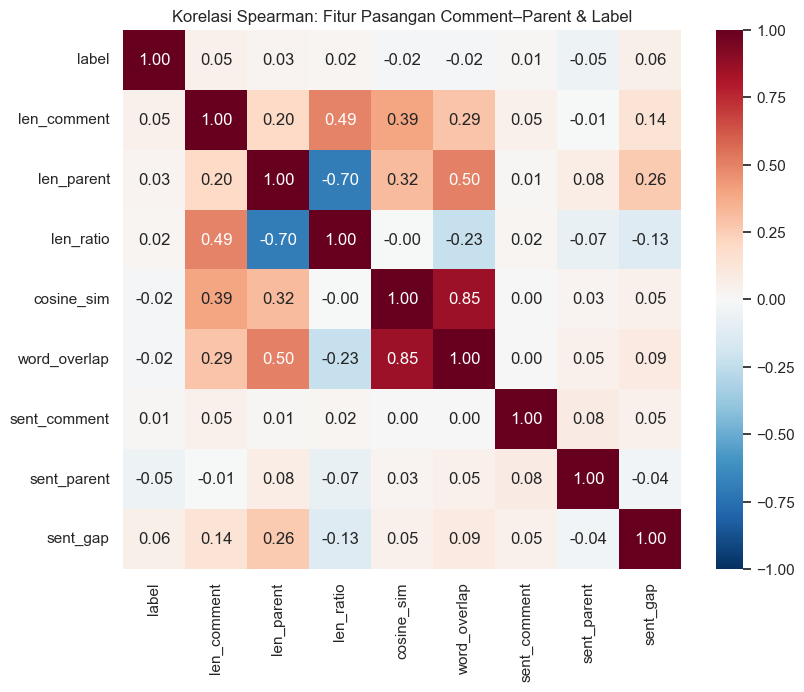

In [22]:
pairs = [("len_comment", "len_parent"), ("sent_comment", "sent_parent")]
corr_rows = []
for name, g in ctx.groupby("label_name"):
    for a, b in pairs:
        corr_rows.append({"Label": name, "Pasangan": f"{a} vs {b}",
                          "Spearman rho": spearmanr(g[a], g[b]).statistic})
corr_cp = pd.DataFrame(corr_rows).pivot(index="Pasangan", columns="Label", values="Spearman rho").round(3)
display(corr_cp)

plt.figure(figsize=(9, 7))
corr = ctx[["label"] + features].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Korelasi Spearman: Fitur Pasangan Comment–Parent & Label")
save_fig("04_pair_feature_correlation")
plt.show()


#### Insight
Pada sarkas, hubungan comment dengan parent lebih lemah:
- panjang: korelasi 0,155 pada sarkas dibanding 0,241 pada bukan sarkas,
- sentimen: korelasi 0,068 pada sarkas dibanding 0,102 pada bukan sarkas.

Artinya comment sarkas cenderung tidak mengikuti nada dan panjang parent-nya. Comment bukan sarkas lebih sering "menyambung" langsung, misalnya membalas parent yang panjang dengan jawaban yang juga panjang, atau membalas nada positif dengan nada positif.

### 6.5 Kemiripan Kata dan Panjang

Grafik pertama menunjukkan sebaran kemiripan kata comment dan parent dalam bentuk ECDF, yaitu grafik yang menunjukkan berapa persen data yang nilainya di bawah angka tertentu. Grafik kedua menunjukkan rasio panjang dan hubungan panjang parent dengan panjang comment.

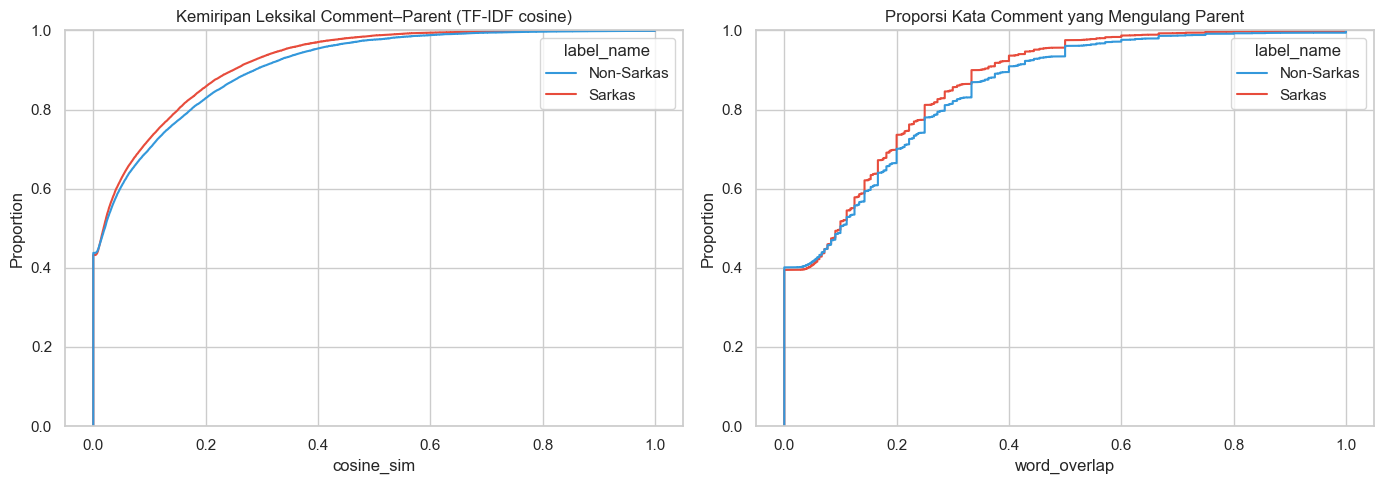

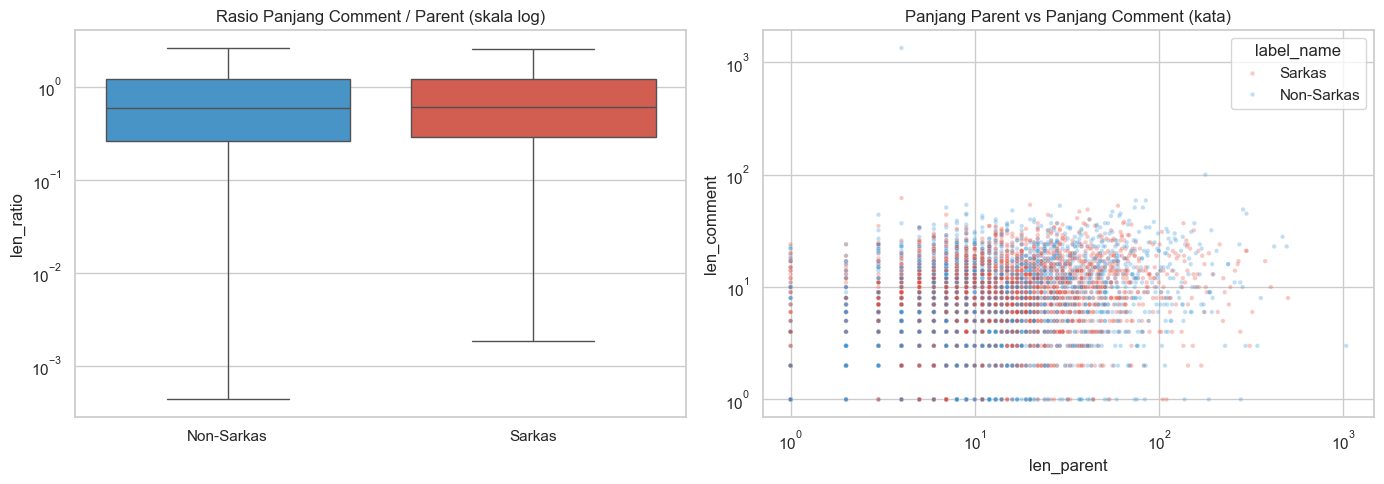

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.ecdfplot(data=ctx, x="cosine_sim", hue="label_name", palette=PALETTE, ax=axes[0])
axes[0].set_title("Kemiripan Leksikal Comment–Parent (TF-IDF cosine)")
sns.ecdfplot(data=ctx, x="word_overlap", hue="label_name", palette=PALETTE, ax=axes[1])
axes[1].set_title("Proporsi Kata Comment yang Mengulang Parent")
plt.tight_layout()
save_fig("04_context_similarity")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=ctx, x="label_name", y="len_ratio", hue="label_name", palette=PALETTE,
            showfliers=False, legend=False, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Rasio Panjang Comment / Parent (skala log)")
axes[0].set_xlabel("")
sample_plot = ctx.sample(5_000, random_state=SEED)
sns.scatterplot(data=sample_plot, x="len_parent", y="len_comment", hue="label_name",
                palette=PALETTE, alpha=0.3, s=10, ax=axes[1])
axes[1].set(xscale="log", yscale="log", title="Panjang Parent vs Panjang Comment (kata)")
plt.tight_layout()
save_fig("04_length_coupling")
plt.show()


#### Insight
Kurva ECDF sarkas dan bukan sarkas hampir menumpuk, dengan sarkas sedikit lebih ke kiri. Median kemiripan TF-IDF-nya 0,018 untuk sarkas dan 0,021 untuk bukan sarkas. Jadi sarkasme bukan soal mengulang kata parent, tetapi soal membalik makna atau nada.

Rasio panjang comment terhadap parent juga hampir sama di kedua kelas (median 0,600 dan 0,585), dan titik-titik di grafik sebaran bercampur tanpa pola yang jelas.

### 6.6 Kontras Sentimen Parent dan Comment

Heatmap ini menunjukkan persentase sarkas untuk setiap kombinasi sentimen parent (baris) dan sentimen comment (kolom). Angka n adalah jumlah pasangan di kotak itu.

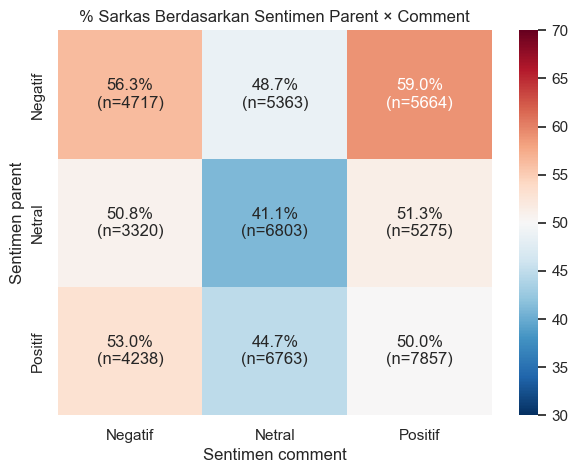

In [24]:
bins = [-1.01, -0.05, 0.05, 1.01]          # ambang standar VADER
names = ["Negatif", "Netral", "Positif"]
ctx["sent_parent_cat"] = pd.cut(ctx["sent_parent"], bins, labels=names)
ctx["sent_comment_cat"] = pd.cut(ctx["sent_comment"], bins, labels=names)

rate = ctx.pivot_table(index="sent_parent_cat", columns="sent_comment_cat",
                       values="label", aggfunc="mean", observed=False) * 100
count = ctx.pivot_table(index="sent_parent_cat", columns="sent_comment_cat",
                        values="label", aggfunc="size", observed=False)
annot = rate.round(1).astype(str) + "%\n(n=" + count.astype(str) + ")"

plt.figure(figsize=(7, 5))
sns.heatmap(rate, annot=annot, fmt="", cmap="RdBu_r", center=50, vmin=30, vmax=70)
plt.title("% Sarkas Berdasarkan Sentimen Parent × Comment")
plt.xlabel("Sentimen comment")
plt.ylabel("Sentimen parent")
save_fig("04_sentiment_contrast_heatmap")
plt.show()


#### Insight
Kombinasi parent negatif dan comment positif punya persentase sarkas tertinggi, yaitu 59,0% (n = 5.664). Sebaliknya, parent dan comment yang sama-sama netral punya persentase terendah, yaitu 41,1% (n = 6.803).

Pola ini sesuai dengan definisi sarkasme: pujian atau nada positif yang dipakai untuk menanggapi hal yang negatif. Kombinasi parent negatif dan comment negatif juga cukup tinggi (56,3%), karena sarkasme kadang disampaikan dengan nada mengeluh.

Walaupun begitu, kotak tertinggi pun hanya 59%, jadi kontras sentimen saja tidak cukup untuk menentukan sarkas.

### 6.7 Contoh Kualitatif: Parent Negatif, Comment Positif, Label Sarkas

Tabel ini menampilkan beberapa contoh sarkas dengan parent yang sangat negatif (skor di bawah -0,5) dan comment yang terdengar sangat positif (skor di atas 0,5).

In [25]:
contrast = ctx[(ctx["label"] == 1) & (ctx["sent_parent"] < -0.5) & (ctx["sent_comment"] > 0.5)]
with pd.option_context("display.max_colwidth", 120):
    display(contrast[["parent_comment", "comment", "sent_parent", "sent_comment"]].head(5))


,parent_comment,comment,sent_parent,sent_comment
25239,Yea they just want to kill us because they are mean people... Nothing to do with us sticking our nose where it doesn...,You're super smart,-0.8360,0.7650
25249,Corruption from the Mayor on down to the meter maids are a good part of the problem as well. It's not just liberals ...,but wait unions are good for an industry...,-0.6757,0.5927
25256,I imagine a similar situation such as when France invaded Mexico in late 1861 in clear defiance of the Monroe Doctri...,Yeah because we all know that Britain was on the verge of supporting the confederacy,-0.5574,0.6249
25272,High turnover of staff in National MP's office and claims of bullying,"Im sure Hoskings will have him on the show soon, he sounds like a real nice chap",-0.5994,0.7650
25313,License to Kill: Wind and Solar Decimate Birds and Bats - IER,Free food,-0.6908,0.5106


### Kesimpulan Analisis Konteks

Contoh di atas menunjukkan pola yang sama. Comment seperti "You're super smart" atau "he sounds like a real nice chap" terdengar memuji, tetapi menjadi sindiran setelah dibaca bersama parent yang negatif.

Dari seluruh bagian 6, sarkasme tidak bisa dikenali dari comment atau parent saja dengan fitur sederhana, karena setiap fitur hanya memberi sinyal lemah. Polanya muncul dari hubungan keduanya, terutama kontras sentimen dan comment pendek yang bergantung pada parent. Karena itu model diberi input parent dan comment sekaligus, supaya mekanisme self-attention pada transformer bisa menangkap hubungan antar-kalimat. Self-attention adalah cara model menghubungkan setiap kata dengan kata lain dalam input, termasuk kata di parent dengan kata di comment.

## 7. Kesiapan Data untuk Modeling

Bagian ini mengecek apakah data sudah siap dipakai model, khususnya panjang input dalam token.

### 7.1 Panjang Token Pasangan Parent dan Comment

Token adalah potongan kata yang dibaca model. Bagian ini menghitung panjang pasangan parent dan comment dalam token, pada sampel 20.000 pasangan, untuk mengecek apakah batas 256 token cukup. Tokenizer yang dipakai sama dengan training, yaitu `roberta-base` dan `distilbert-base-cased`.

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (710 > 512). Running this sequence through the model will result in indexing errors
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (769 > 512). Running this sequence through the model will result in indexing errors


,Median,P95,P99,Max,% terpotong (> 256)
Model,,,,,
roberta-base,35.0,120.0,242.01,2104,0.86
distilbert-base-cased,37.0,127.0,261.00,3777,1.03


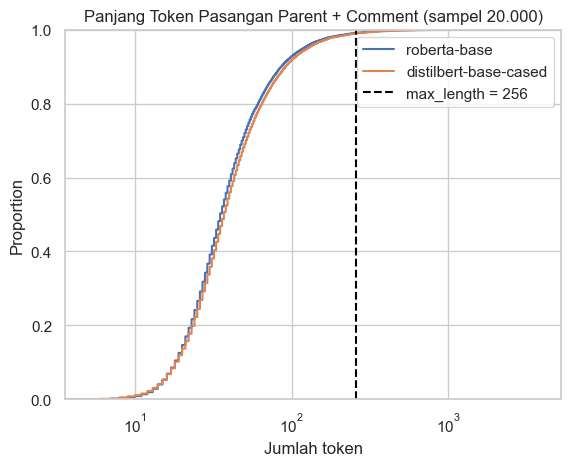

In [26]:
MAX_LEN = 256
tok_sample = df.sample(20_000, random_state=SEED)
rows = []
for model_name in ["roberta-base", "distilbert-base-cased"]:      # model yang sama dengan training
    tok = AutoTokenizer.from_pretrained(model_name)
    enc = tok(tok_sample["parent_clean"].tolist(), tok_sample["comment_clean"].tolist(), truncation=False)
    n_tok = pd.Series([len(ids) for ids in enc["input_ids"]])
    rows.append({"Model": model_name, "Median": n_tok.median(), "P95": n_tok.quantile(0.95),
                 "P99": n_tok.quantile(0.99), "Max": n_tok.max(),
                 f"% terpotong (> {MAX_LEN})": (n_tok > MAX_LEN).mean() * 100})
    sns.ecdfplot(n_tok, label=model_name)
token_lengths = pd.DataFrame(rows).set_index("Model").round(2)
display(token_lengths)
token_lengths.to_csv(TAB_DIR / "eda_token_lengths.csv")

plt.axvline(MAX_LEN, color="black", ls="--", label=f"max_length = {MAX_LEN}")
plt.xscale("log")
plt.title("Panjang Token Pasangan Parent + Comment (sampel 20.000)")
plt.xlabel("Jumlah token")
plt.legend()
save_fig("08_token_length_ecdf")
plt.show()

#### Insight
Median panjang pasangan parent dan comment adalah 35 token (RoBERTa) dan 37 token (DistilBERT). Dengan batas 256 token, hanya 0,86% (RoBERTa) dan 1,03% (DistilBERT) pasangan yang terlalu panjang.

Angka ini dekat dengan hasil di `03_tokenization` yang memakai seluruh data train (0,85% dan 0,99%). Jadi batas 256 token sudah mencakup sekitar 99% data. Kalau input terlalu panjang, yang dipotong adalah bagian akhir parent, sedangkan comment tetap utuh.

### 7.2 Pembagian Data

Penelitian ini memakai seluruh data, bukan subset 200.000 pasangan seperti rencana awal di proposal. Karena itu bagian representativitas subset tidak diperlukan lagi.

Pembagian data menjadi train, validasi, dan test (80/10/10) dilakukan di `02_preprocessing`. Pembagiannya per kelompok comment, jadi comment yang sama selalu masuk ke bagian yang sama dan tidak bocor ke data test. Hasilnya 799.459 data train, 100.276 data validasi, dan 101.129 data test.

## 8. Kesimpulan EDA

1. Data mentah relatif bersih. Dari 1.010.826 pasangan, tersisa 1.000.864 pasangan setelah cleaning ringan (99,01%), sama persis dengan data training di `02_preprocessing`. Yang dibuang adalah comment kosong (55), teks kosong setelah cleaning (9), label bertentangan (142), duplikat (1.157), dan artefak `/s` (8.599). Labelnya hampir seimbang (49,59% sarkas).
2. Fitur permukaan bukan pembeda sarkasme. Median panjang comment sama di kedua kelas (9 kata), median skor sama (2), dan proporsi sarkas per hari hanya berkisar 48,53% sampai 50,17%. Topik subreddit lebih berpengaruh, karena sarkas jauh lebih sering muncul di politics, worldnews, dan news.
3. Ada pola kata yang khas untuk sarkas, seperti "Yeah", "sure", "obviously", "good thing", dan "everyone knows". Tetapi banyak kata yang muncul di kedua kelas, dan daftar n-gram bukan sarkas terganggu oleh spam yang diulang-ulang. Jadi frekuensi kata saja tidak cukup.
4. Hubungan comment dan parent penting. Pada sarkas, korelasi panjang comment dan parent lebih lemah (0,155 dibanding 0,241), begitu juga korelasi sentimennya (0,068 dibanding 0,102). Kombinasi parent negatif dan comment positif punya persentase sarkas tertinggi (59,0%). Tetapi setiap fitur sederhana hanya punya effect size sangat kecil (Cliff's delta paling besar 0,072), jadi sarkasme muncul dari hubungan comment dan parent, bukan dari satu fitur.
5. Batas 256 token sudah cukup. Hanya 0,86% (RoBERTa) dan 1,03% (DistilBERT) pasangan yang terpotong, dan yang dipotong adalah akhir parent.

Temuan nomor 4 menjadi alasan model diberi input parent dan comment sekaligus. Apakah parent benar-benar membantu model diuji di notebook 07.